---
---

<h1><center><ins>Exercise Sheet 3</ins></center></h1>
<h2><center>Numerical Methods <br><br>

---
---

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from numpy import exp

## Exercise 1 - Root finding algorithms

**(A)** Implement the *bisection*, *secant*, *false position* and *Newton-Raphson* root finding methods, by coding your own version of these algorithms. Make sure to test your codes, checking that indeed they are able to find the root of a function (to do this, you can for example pickaanalytic function that allows you to test the codes and for which you can compute the roots analytically).

**(B)** Use your implementation of the 4 root finding methods (from part **A**) to compute the root of the function:

$$f(x) = e^x - 1 - x - \frac{x^2}{2}$$

in the interval $x\in[-1,2]$. For each method, print out the position of the root and the number of iterations needed to reach it.

**(C)** Discuss your results, commenting how the methods compare to one another. Which one is the fastest/slowest? Why? What is the impact of the points you selected to start your iterations?

In [3]:
def test1(x):               # I used this as a test function, it has two roots, at +/- 1
    global calls            # I want to count how often the function is evaluated
    calls += 1              # so I declare it as global, so it is persistent over various calls
    return x*x - 1

def f(x):                   # This is the function from the problem set
    global calls
    calls += 1
    return exp(x) - 1 - x - x*x/2

def df(x):                  # This is the derivative, which is needed by Newton-Raphson
    global calls            # I want to count how often the function is evaluated
    calls += 1              # so I declare it as global, so it is persistent over various calls
    return exp(x) -1 - x

def Bisect(f, a, b, eps, maxiter=1000):
    """ 
    Bisect method for root finding
    INPUT:
    f       reference to function, for which root should be found
    a       lower boundary
    b       upper boundary
    eps     epsilon, desired accuracy
    maxiter maximum number of iteration, defaults to 1000
    RETURNS:
        The root
        function value at root (residual)
        number of iteration
    """
    if b <= a:
        raise ValueError(f"Upper boundary not greater than lower boundary")
    if not callable(f):
        raise ValueError("First argument is not a function")

    iter = 0
    ay, by = f(a), f(b)     # evaluate f
    if (abs(ay)) < eps:
        return a, ay, iter
    if (abs(by)) < eps:
        return b, by, iter
    if ay * by >= 0:
        raise ValueError(f"Boundaries do not bracket a root! f({a})={ay}, f({b})={by}")

    while iter < maxiter:   # make sure we do not iterate forever
        xm = (a + b) / 2
        ym = f(xm)
        if (abs(ym) < eps) or abs(b - a) < eps:
            return xm, ym, iter
        if (ay * ym) < 0:   # left interval brackets root
            b = xm          # set new upper boundary to midpoint
            by = f(b)       # prepare value for next iteration
        if (by * ym) < 0:
            a= xm
            ay = f(a)
        iter += 1

    raise ValueError("too may iterations")

def Secant(f, a, b, eps, maxiter=1000):
    """ Secant method of root finding"""
    if b <= a:
        raise ValueError(f"Upper boundary not greater than lower boundary")
    if not callable(f):
        raise ValueError("First argument is not a function")

    iter = 0
    ay, by = f(a), f(b)
    if (abs(ay)) < eps:
        return a, ay, iter
    if (abs(by)) < eps:
        return b, by, iter
    if ay * by >= 0:
        raise ValueError(f"Boundaries do not bracket a root! f({a})={ay}")
    
    while iter < maxiter:
        xm = (b * ay -a * by) / (ay - by)
        ym = f(xm)
        if (abs(ym) < eps) or abs(b - a) < eps:
            return xm, ym, iter
        a, ay = b, by
        b, by = xm, ym
        iter += 1
    raise ValueError("too may iterations")

def FalsePos(f, a, b, eps, maxiter=1000):
    """False Position method of root finding """
    if b <= a:
        raise ValueError(f"Upper boundary not greater than lower boundary")
    if not callable(f):
        raise ValueError("First argument is not a function")

    iter = 0
    ay, by = f(a), f(b)
    if (abs(ay)) < eps:
        return a, ay, iter
    if (abs(by)) < eps:
        return b, by, iter
    if ay * by >= 0:
        raise ValueError(f"Boundaries do not bracket a root! f({a})={ay}")
    while iter < maxiter:
#        print(iter, a, ay, b, by)
        xm = (b * ay -a * by) / (ay - by)
        ym = f(xm)
        if (abs(ym) <   eps) or abs(b - a) < eps:
            return xm, ym, iter
        if (ay * ym) < 0:
            b, by = xm, ym
        else:
            a, ay = xm, ym
        iter += 1
    raise ValueError("too may iterations")

def NewtRaph(f, df, x, eps, maxiter=1000):
    """Newton-Raphson method of root finding """
    if not callable(f):
        raise ValueError("First argument is not a function")
    if not callable(df):
        raise ValueError("Second argument is not a function")

    yn = f(x)
    iter = 0
    if (abs(yn) < eps):
        return x, yn, iter
    while iter < maxiter:
        xn = x - yn / df(x)
        yn = f(xn)
        if (abs(yn) < eps) or abs(x - xn) < eps:
            return xn, yn, iter
        x = xn
        y = yn
        iter += 1
    raise ValueError("too may iterations")

epsilon = 1e-6
a, b = -2, 1

calls = 0
xr, resid, iter = Bisect(f, a, b, epsilon) 
print(f"Bisect: root = {xr}, residual = {resid}. Needed {iter} iterations. {calls} evaluations of f")
%timeit Bisect(f, a, b, epsilon)

calls = 0
xr, resid, iter = Secant(f, a, b, epsilon)
print(f"Secant: root = {xr}, residual = {resid}. Needed {iter} iterations. {calls} evaluations of f")
%timeit Secant(f, a, b, epsilon)

calls = 0
xr, resid, iter = FalsePos(f, a, b, epsilon, 100000000)
print(f"False position: root = {xr}, residual = {resid}. Needed {iter} iterations. {calls} evaluations of f")
%timeit FalsePos(f, a, b, epsilon, 100000000)

calls = 0
xr, resid, iter = NewtRaph(f, df, 0.5, epsilon)
print(f"Newton-Raphson: root = {xr}, residual = {resid}. Needed {iter} iterations. {calls} evaluations of f or df")
%timeit NewtRaph(f, df, 0.5, epsilon)

Bisect: root = 0.015625, residual = 6.382741857269281e-07. Needed 5 iterations. 13 evaluations of f
4.87 μs ± 107 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)
Secant: root = 0.016187711583366408, residual = 7.098471086155089e-07. Needed 12 iterations. 15 evaluations of f
7.73 μs ± 58.9 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)
False position: root = 0.018142776022225516, residual = 9.998445343998056e-07. Needed 3828 iterations. 3831 evaluations of f
2 ms ± 36.9 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
Newton-Raphson: root = 0.0138551378719554, residual = 4.4482293545802993e-07. Needed 8 iterations. 19 evaluations of f or df
5.18 μs ± 48.2 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


In most cases, Newton-Raphson has the lowest number of iterations. However, it should be less than half of the iterations compared with other methods in order to be better, because additionally to the the evaluations of the function we have the evaluations of the derivative, and this is not always the case.

There is a big impact of the starting interval. If I chose a symmetric one, like [-2, 2], Bisect obviously is immediately on the root. For the thee methods using intervals, I can use the same interval, and compare directly, for Newton-Raphson I give just one starting value, so this is difficult to compare.

In all cases, the False Position was by far the worst, much worse than any other method. This is also reflected in the timing. The other three methods need about 6 μs, False Position needs around 2 ms.

Bisect is the winner by a narrow margin. I suspect that in other cases Newton-Raphson fares better.

## Exercise 2 - Sets of linear equations

Determine the solution to the following set of linear equations:

$$ 
\begin{cases}
5 x_1 + 3 x_2 &= 15 \\
x_1 - 4 x_2 &= -2 \ ,
\end{cases}
$$

where $x_1$ and $x_2$ are the variables of interest.

**(A)** Formulate the problem by using the matrix representation, as we saw in class, clearly defining the coefficient matrix and the vector of right-hand-side values.

**(B)** Using the appropriate built-in python functions, carry out the LU decomposition of the coefficient matrix, and print out the L and U matrices separately. Solve the set of equations and check that the solution is indeed valid.

**(C)** What is the solution to the following set of equations? 

$$ 
\begin{cases}
x_1 - 4 x_2 &= 3 \\
5 x_1 + 3 x_2 &= -7
\end{cases}
$$

Print out the solution, and motivate the steps you took to solve it.

In [ ]:
from scipy.linalg import lu, lu_factor, lu_solve

A = np.array([[5, 3], [1, -4]])
b = np.array([15, -2])

P, L, U = lu(A)                     # lu returns permutation, lower diagonal and upper diagonal

print(f'Original matrix:\n{A}')
print(f'Lower diagonal:\n{L}')
print(f'Upper diagonal:\n{U}')

LU, PIV = lu_factor(A)              # lu_factor is what I really need, because it return upper diag and pivot

x = lu_solve((LU, PIV), b)          # and lu_solve needs upper diag and pivot
print(f'Solution: {x}')             # now I could easily also solve for other RHS vectors
print(f'Test A x = {A @ x}')        # @ is the matrix multiplication
assert np.isclose(A @ x, b).all(), "x is not the correct solution"
                                    # I use isclose in the assertion in order to avoid wrong error
A = np.array([[1, -4], [5, 4]])     #    error reprots due to small numerical differences
b = np.array([3, -7])

LU, PIV = lu_factor(A)

print()
print('Second system:')
x = lu_solve((LU, PIV), b)
print(f'Solution: {x}')
print(f'Test A x = {A @ x}')


Original matrix:
[[ 5  3]
 [ 1 -4]]
Lower diagonal:
[[1.  0. ]
 [0.2 1. ]]
Upper diagonal:
[[ 5.   3. ]
 [ 0.  -4.6]]
Solution: [2.34782609 1.08695652]
Test A x = [15. -2.]

Second system:
Solution: [-0.66666667 -0.91666667]
Test A x = [ 3. -7.]


## Exercise 3 - The Newton fractal

In the lecture, we discussed the Newton fractal. The aim of this exercise is to plot it. 

**(A)** Generate a complex plane of numbers between [-2,2] for the real and imaginary parts. You can use the function np.linspace for the Re and Im parts (assume a sufficient number of points, for instance, a few hundred), and then use np.meshgrid to create a full Re, Im grid. You create the complex numbers by using Z = X + 1j * Y. This is the initial set of complex points for your iteration.

**(B)** For every starting point in your grid that you generated in (A), run the Newton-Raphson iteration as $$z_{i+1} = z_{i} - \frac{z_{i}^3 - 1}{3 z_{n}^2} $$ Test how may times you need to run the iteration for the values to converge to one of the three roots (tip: several tens of iteration should be sufficient).

**(C)** Calculate analytically or look up online the three roots of the function $$f(z) = z^3 - 1$$ and store them. For each point you have obtained in (B), calculate the distance to every root using, for instance, np.abs. and determine the nearest root. 

**(D)** Plot the result. You can use the function plt.imshow or a similar solution. Assign the color to each plot according to the nearest root. Add the three roots using e.g. plt.scatter.

Reached a stable solution after 47 iterations


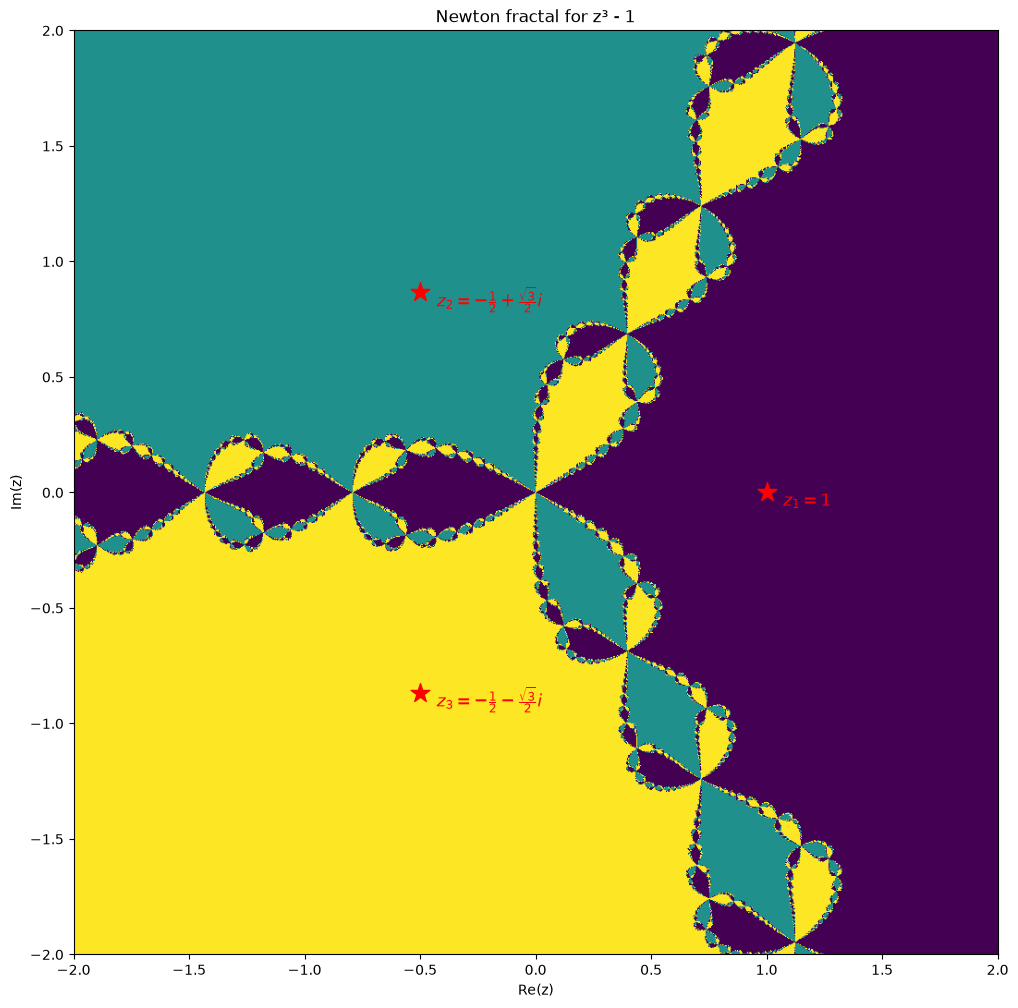

In [21]:
import matplotlib.pyplot as plt
import numpy as np

grid = np.linspace(-2, 2, 1000)     # using an even number of points I avoid the origin (0, 0j)
A, B = np.meshgrid(grid, grid)      # where I would have division by zero

Z = A + B * 1j                      # 2D array of starting points in the complex number plane

x1 = 1 + 0j                         # first root, easy to guess
x2 = -0.5 + np.sqrt(3) / 2 * 1j     # other two root follow from separating the first root
x3 = -0.5 - np.sqrt(3) / 2 * 1j
xr = [x1.real, x2.real, x3.real]    # xr, xi used for the scatter plot of the 3 analytic roots
xi = [x1.imag, x2.imag, x3.imag]

def frac(C):                        # Newton-Raphson
    return C - (C**3 - 1) / (3 * C**2)

iter = 0
nearest = np.zeros_like(Z, dtype=int)
for i in range(100):
    iter += 1
    Z = frac(Z)
                                    # 100 iteration is the safety net
                                    # but when all points are close enough to satisfying the equation
                                    # we break the iteration
    if np.all(abs(Z**3 - 1) < 1e-6):
        print(f'Reached a stable solution after {iter} iterations')
        break

dist_x1 = abs(Z - x1)               # distances to roots
dist_x2 = abs(Z - x2)               # NB: for showing the fractal, there exists a much nicer way: 
dist_x3 = abs(Z - x3)               # set up an array angle = arg(Z)
mask1 = (dist_x1 < dist_x2) & (dist_x1 < dist_x3)   # this will point into 0, 120°, -120°
mask2 = (dist_x2 < dist_x3) & (dist_x2 < dist_x1)   # and gives the same pretty image
mask3 = (dist_x3 < dist_x1) & (dist_x3 < dist_x2)   # without these cumbersome distances and masks
nearest[mask1] = 1
nearest[mask2] = 2
nearest[mask3] = 3

#print(nearest)

labels = [
    r'$z_1 = 1$',
    r'$z_2 = -\frac{1}{2} + \frac{\sqrt{3}}{2}i$',  # r (raw) strings escape special characters used in the LaTex formulae
    r'$z_3 = -\frac{1}{2} - \frac{\sqrt{3}}{2}i$'
]
   
plt.figure(figsize=(12, 12))

plt.imshow(                         # imshow() would show me pixel coordinates
    nearest,
    extent=[-2, 2, -2, 2],          # with extent I scale to my actual coordinates
    origin="lower",                 # and imshow() puts the origin by default in the upper left corner
    cmap='viridis',
    alpha=1
)
#plt.colorbar(label="index of root")    # we could put a colorbar, but it is not really helpful here
                                    # mark the analytical roots
plt.scatter(xr, xi, c='red', s=200, marker='*')

for j in range(3):
    plt.annotate(                   # and give them nice labels
        labels[j],
        (xr[j], xi[j]),
        xytext=(12, -10),
        textcoords='offset points',
        fontsize=12,
        color='red',
        )

plt.xlabel("Re(z)")
plt.ylabel("Im(z)")
plt.title("Newton fractal for z³ - 1")

plt.show()